In [1]:


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
# Load the MNIST dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


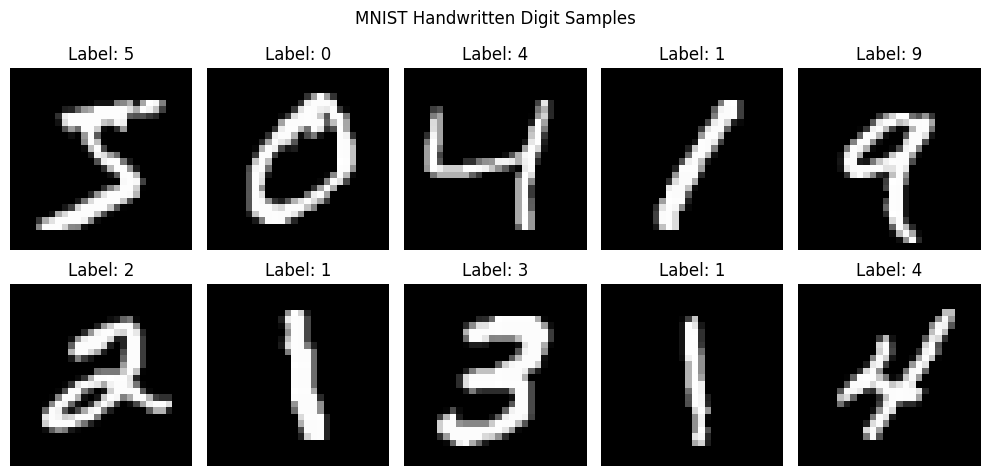

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digit Samples")
plt.tight_layout()
plt.show()

In [4]:
# Normalize pixel values from 0–255 to 0–1

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add the channel dimension for the CNN

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Build the CNN model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the CNN model

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("Model training completed successfully!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9208 - loss: 0.2677 - val_accuracy: 0.9837 - val_loss: 0.0579
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9778 - loss: 0.0759 - val_accuracy: 0.9880 - val_loss: 0.0425
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9832 - loss: 0.0543 - val_accuracy: 0.9898 - val_loss: 0.0374
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9867 - loss: 0.0439 - val_accuracy: 0.9913 - val_loss: 0.0340
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9882 - loss: 0.0378 - val_accuracy: 0.9893 - val_loss: 0.0352
Model training completed successfully!


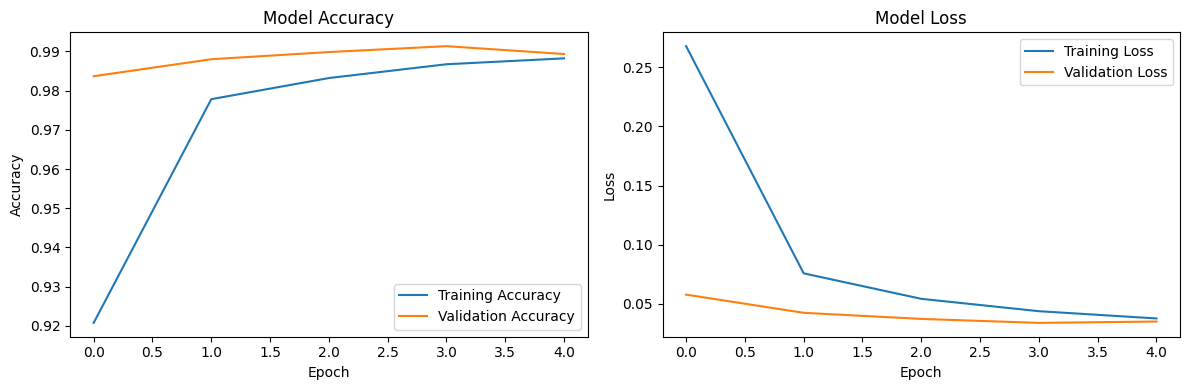

In [7]:
# Plot training and validation accuracy

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Evaluate the trained model

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Test Loss: 0.0288
Test Accuracy: 0.9904
Test Accuracy (%): 99.04%


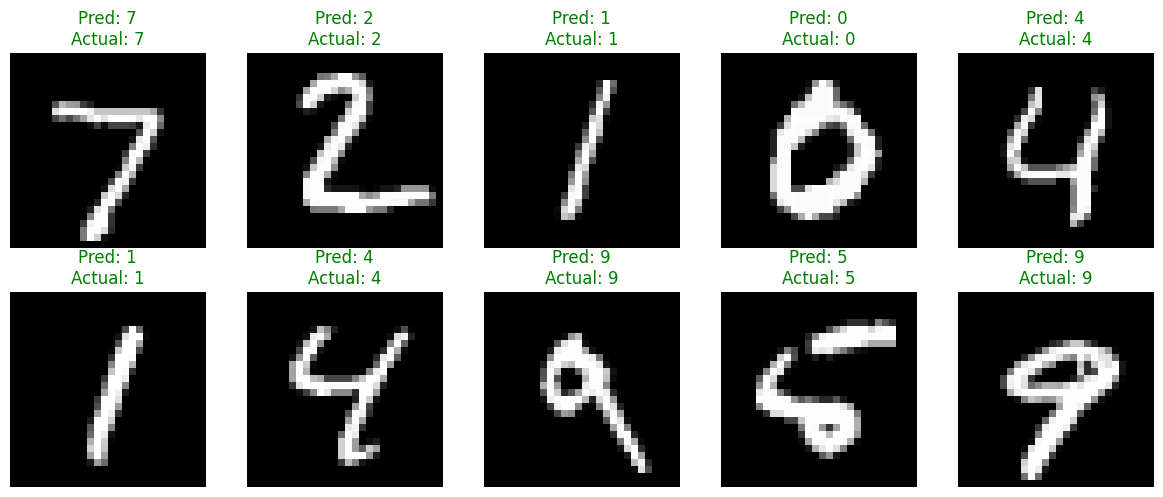

In [9]:
# Predict the first 10 test images

predictions = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")

    color = "green" if predicted_labels[i] == y_test[i] else "red"

    plt.title(
        f"Pred: {predicted_labels[i]}\nActual: {y_test[i]}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9949    0.9959    0.9954       980
           1     0.9956    0.9930    0.9943      1135
           2     0.9885    0.9952    0.9918      1032
           3     0.9872    0.9931    0.9901      1010
           4     0.9959    0.9878    0.9918       982
           5     0.9843    0.9854    0.9849       892
           6     0.9906    0.9885    0.9896       958
           7     0.9789    0.9942    0.9865      1028
           8     0.9959    0.9867    0.9912       974
           9     0.9920    0.9832    0.9876      1009

    accuracy                         0.9904     10000
   macro avg     0.9904    0.9903    0.9903     10000
weighted avg     0.9904    0.9904    0.9904     10000



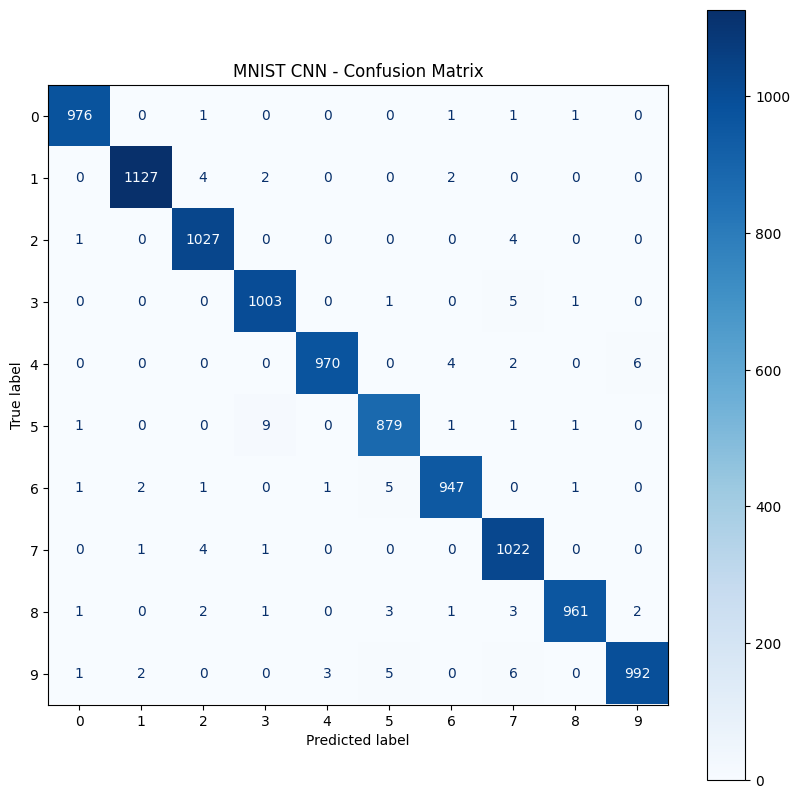

In [10]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Predict all test images
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("MNIST CNN - Confusion Matrix")
plt.show()

In [11]:
import json
import pandas as pd

# Save the trained model
model.save("handwritten_digit_cnn.keras")

# Save evaluation metrics
metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_accuracy_percent": float(test_accuracy * 100)
}

with open("evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Save classification report
report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "classification_report.csv"
)

print("Model and evaluation files saved successfully!")

Model and evaluation files saved successfully!


In [13]:
from google.colab import files

files.download("handwritten_digit_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
files.download("evaluation_metrics.json")
files.download("classification_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
%pip install -q importlib_resources tensorflow-datasets

In [20]:
import tensorflow as tf
import tensorflow_datasets as tfds
import importlib_resources

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("importlib_resources installed successfully!")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
importlib_resources installed successfully!


In [21]:
(train_ds, test_ds), info = tfds.load(
    "emnist/byclass",
    split=["train", "test"],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Number of classes:", info.features["label"].num_classes)
print("Training examples:", info.splits["train"].num_examples)
print("Testing examples:", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.NYK1JC_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/byclass/incomplete.NYK1JC_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/byclass/3.1.0. Subsequent calls will reuse this data.
Dataset loaded successfully!
Number of classes: 62
Training examples: 697932
Testing examples: 116323


Number of classes: 62
Training examples: 697932
Testing examples: 116323


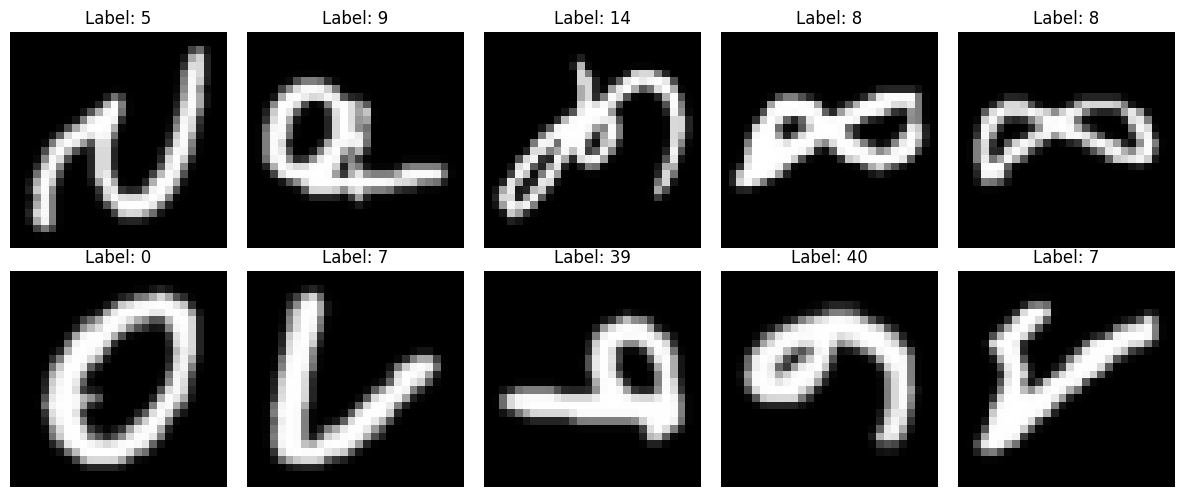

In [22]:

# Check the EMNIST dataset

print("Number of classes:", info.features["label"].num_classes)
print("Training examples:", info.splits["train"].num_examples)
print("Testing examples:", info.splits["test"].num_examples)

# Display some sample images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, (image, label) in enumerate(train_ds.take(10)):
    ax = axes[i // 5, i % 5]
    ax.imshow(image.numpy().squeeze(), cmap="gray")
    ax.set_title(f"Label: {label.numpy()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


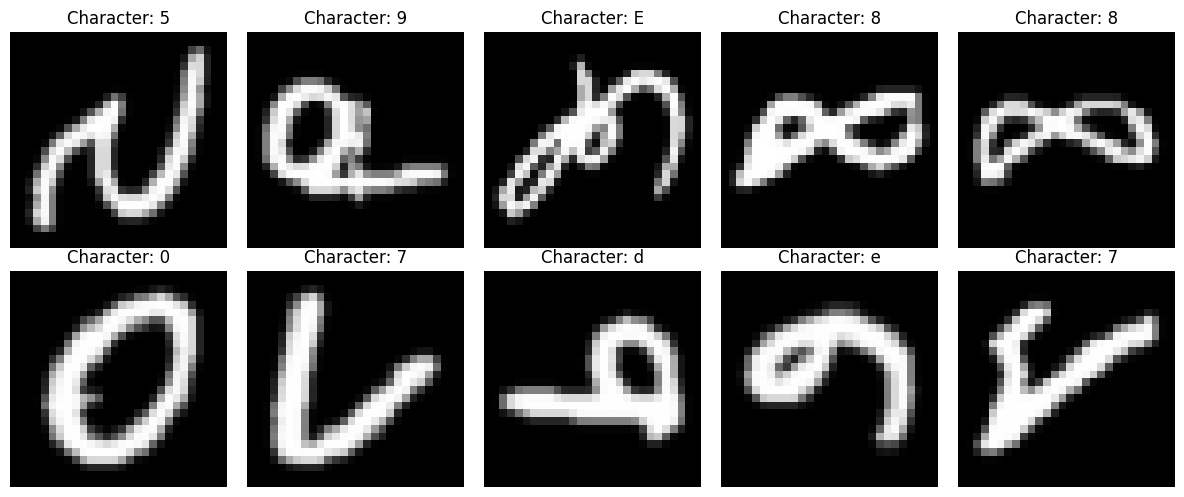

In [23]:

import matplotlib.pyplot as plt

# Character labels: digits, uppercase, lowercase
def get_character(label):
    label = int(label)

    if label < 10:
        return str(label)
    elif label < 36:
        return chr(ord('A') + label - 10)
    else:
        return chr(ord('a') + label - 36)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, (image, label) in enumerate(train_ds.take(10)):
    axes[i // 5, i % 5].imshow(
        image.numpy().squeeze(), cmap="gray"
    )
    axes[i // 5, i % 5].set_title(
        f"Character: {get_character(label.numpy())}"
    )
    axes[i // 5, i % 5].axis("off")

plt.tight_layout()
plt.show()


In [24]:

import tensorflow as tf

# Prepare images and labels
def preprocess_emnist(image, label):
    # Correct EMNIST image orientation
    image = tf.transpose(image, perm=[1, 0, 2])

    # Normalize pixel values
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

# Create efficient dataset pipelines
train_data = (
    train_ds
    .map(preprocess_emnist, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(10000)
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

test_data = (
    test_ds
    .map(preprocess_emnist, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

print("EMNIST preprocessing completed!")


EMNIST preprocessing completed!


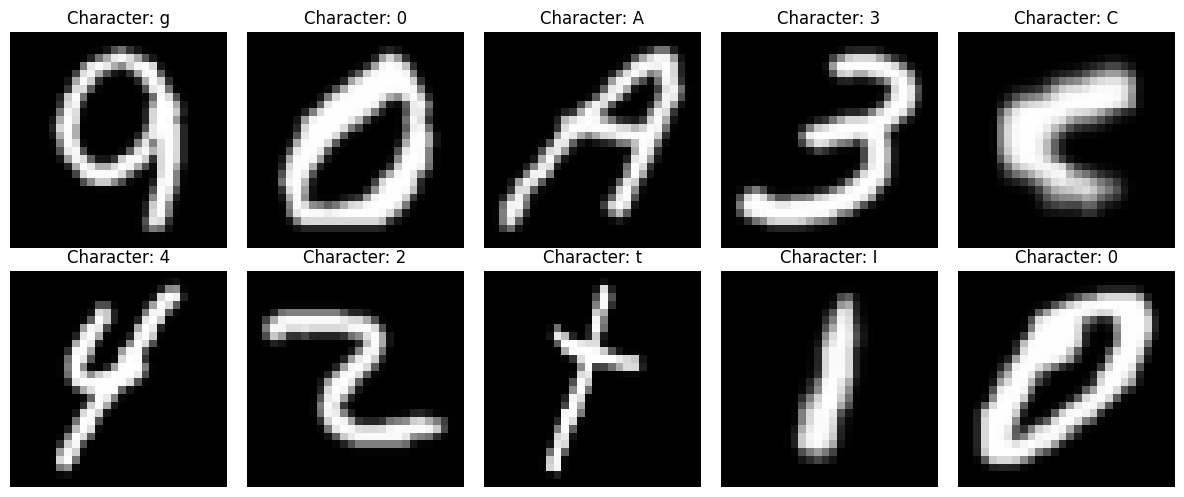

In [25]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, (image, label) in enumerate(train_data.unbatch().take(10)):
    axes[i // 5, i % 5].imshow(
        image.numpy().squeeze(), cmap="gray"
    )
    axes[i // 5, i % 5].set_title(
        f"Character: {get_character(label.numpy())}"
    )
    axes[i // 5, i % 5].axis("off")

plt.tight_layout()
plt.show()


In [26]:

# Build CNN model for handwritten character recognition

emnist_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    # 62 output classes
    tf.keras.layers.Dense(62, activation="softmax")
])

emnist_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

emnist_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 62)             │         7,998 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 231,742 (905.24 KB)

 Trainable params: 231,742 (905.24 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:

history_emnist = emnist_model.fit(
    train_data,
    epochs=5,
    validation_data=test_data
)


Epoch 1/5
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 94s 16ms/step - accuracy: 0.7966 - loss: 0.6318 - val_accuracy: 0.8482 - val_loss: 0.4242
Epoch 2/5
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 84s 15ms/step - accuracy: 0.8420 - loss: 0.4545 - val_accuracy: 0.8583 - val_loss: 0.3877
Epoch 3/5
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 84s 15ms/step - accuracy: 0.8505 - loss: 0.4230 - val_accuracy: 0.8601 - val_loss: 0.3744
Epoch 4/5
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 83s 15ms/step - accuracy: 0.8551 - loss: 0.4038 - val_accuracy: 0.8640 - val_loss: 0.3663
Epoch 5/5
5453/5453 ━━━━━━━━━━━━━━━━━━━━ 83s 15ms/step - accuracy: 0.8586 - loss: 0.3911 - val_accuracy: 0.8658 - val_loss: 0.3625


In [28]:

# Evaluate the EMNIST model on the test dataset

test_loss_emnist, test_accuracy_emnist = emnist_model.evaluate(
    test_data
)

print(f"Test Loss: {test_loss_emnist:.4f}")
print(f"Test Accuracy: {test_accuracy_emnist * 100:.2f}%")


909/909 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.8658 - loss: 0.3625
Test Loss: 0.3625
Test Accuracy: 86.58%


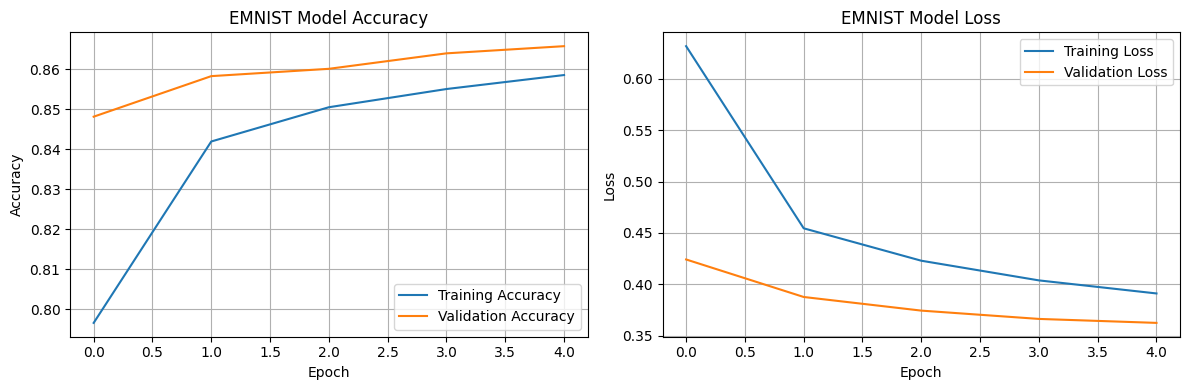

In [29]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_emnist.history["accuracy"], label="Training Accuracy")
plt.plot(history_emnist.history["val_accuracy"], label="Validation Accuracy")
plt.title("EMNIST Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_emnist.history["loss"], label="Training Loss")
plt.plot(history_emnist.history["val_loss"], label="Validation Loss")
plt.title("EMNIST Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


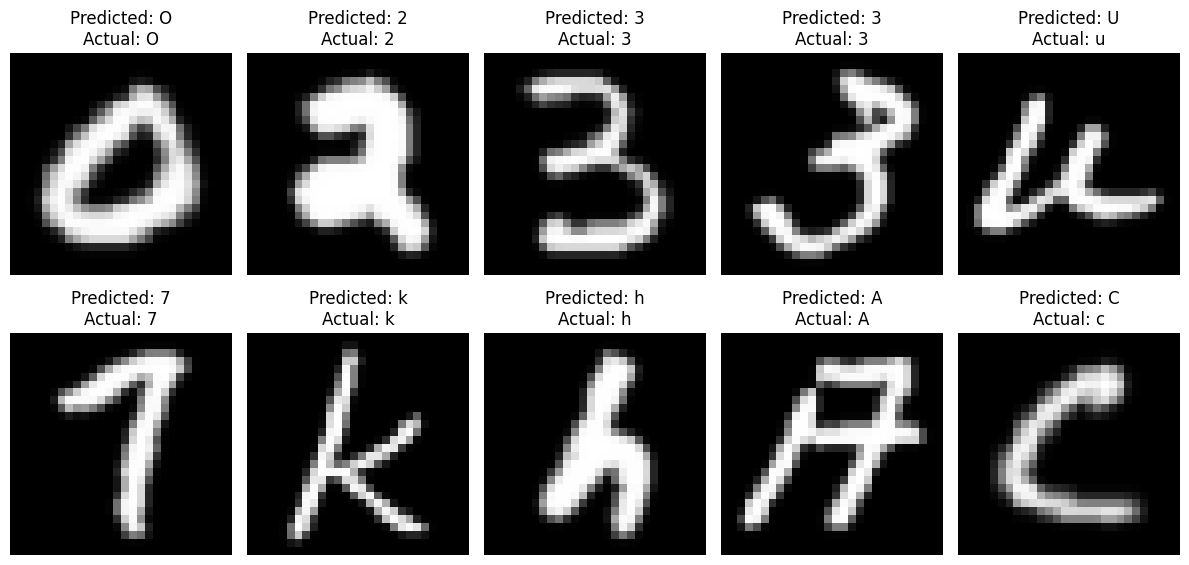

In [30]:

# Convert predicted class numbers to characters
def decode_character(label):
    if label < 10:
        return str(label)
    elif label < 36:
        return chr(ord("A") + label - 10)
    else:
        return chr(ord("a") + label - 36)

plt.figure(figsize=(12, 6))

for images, labels in test_data.take(1):
    predictions = emnist_model.predict(images, verbose=0)

    for i in range(10):
        plt.subplot(2, 5, i + 1)

        predicted_label = predictions[i].argmax()
        actual_label = int(labels[i].numpy())

        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(
            f"Predicted: {decode_character(predicted_label)}\n"
            f"Actual: {decode_character(actual_label)}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()


In [31]:

import json
import pandas as pd

# Save the trained character recognition model
emnist_model.save("handwritten_character_cnn.keras")

# Save evaluation metrics
metrics = {
    "model": "EMNIST CNN",
    "classes": 62,
    "test_accuracy": float(test_accuracy_emnist),
    "test_loss": float(test_loss_emnist),
    "epochs": 5
}

with open("emnist_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Model and evaluation metrics saved successfully!")


Model and evaluation metrics saved successfully!


In [32]:

from google.colab import files

files.download("handwritten_character_cnn.keras")
files.download("emnist_metrics.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

%pip -q install gradio pillow


In [38]:

import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps

# Load your saved model
character_model = tf.keras.models.load_model(
    "handwritten_character_cnn.keras"
)

def decode_character(label):
    if label < 10:
        return str(label)
    elif label < 36:
        return chr(ord("A") + label - 10)
    return chr(ord("a") + label - 36)



def preprocess_character(image, transpose_image=False):
    image = ImageOps.grayscale(image)
    image = ImageOps.autocontrast(image)
    arr = np.array(image)

    # Convert to white handwriting on black background
    if np.mean(arr) > 127:
        arr = 255 - arr

    arr[arr < 40] = 0

    # Crop the character
    ys, xs = np.where(arr > 40)
    if len(xs) == 0:
        return None, None

    arr = arr[ys.min():ys.max()+1, xs.min():xs.max()+1]
    cropped = Image.fromarray(arr)
    cropped.thumbnail((20, 20))

    # Center on a 28x28 canvas
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(
        cropped,
        ((28 - cropped.width)//2, (28 - cropped.height)//2)
    )

    x = np.array(canvas).astype("float32") / 255.0

    if transpose_image:
        x = x.T

    return x.reshape(1, 28, 28, 1), canvas


def predict_character(image):
    if image is None:
        return {}, None

    results = {}

    # Test both orientations
    for transpose in [True, False]:
        x, preview = preprocess_character(image, transpose)

        if x is None:
            return {"No character detected": 1.0}, None

        probabilities = character_model.predict(x, verbose=0)[0]
        top_indices = np.argsort(probabilities)[-3:][::-1]

        orientation = "Transposed" if transpose else "Normal"

        for i in top_indices:
            char = decode_character(int(i))
            results[f"{orientation}: {char}"] = float(probabilities[i])

    # Show the correctly preprocessed image used by the
    # transposed orientation
    _, preview = preprocess_character(image, True)

    return results, preview


In [39]:

# Launch the Gradio application

demo = gr.Blocks(theme=gr.themes.Soft())

with demo:
    gr.Markdown("# Handwritten Character Recognition")
    gr.Markdown("Upload one handwritten digit or letter.")

    input_image = gr.Image(type="pil", label="Upload character")
    output = gr.Label(num_top_classes=6, label="Predictions")
    preview = gr.Image(type="pil", label="Preprocessed image")

    button = gr.Button("Recognize Character", variant="primary")

    button.click(
        fn=predict_character,
        inputs=input_image,
        outputs=[output, preview]
    )

demo.launch(share=True)


/tmp/ipykernel_2537/1561208144.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  demo = gr.Blocks(theme=gr.themes.Soft())


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e88b957fb61a7c49a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
